# California Housing Price Prediction

This notebook predicts median house values in California using three regression models: Ordinary Least Squares, Ridge, and Lasso. It compares their performance using RMSE, MAE, and R², then examines residuals to see where the models overestimate or underestimate house values.

The Task 2 starter file, `housing.csv`, contains 20,640 observations and 10 columns. The target is `median_house_value`. The nine predictors include geographic coordinates, median income, counts of rooms and households, and the categorical feature `ocean_proximity`. Each row represents a California census block group from the 1990 U.S. Census. For each group, `median_income` records median household income in units of 10,000 US dollars, and `median_house_value` records median house value in US dollars.

## Load and inspect the data

In [1]:
import pandas as pd

housing = pd.read_csv("housing.csv")

print(f"Rows: {housing.shape[0]:,} | Columns: {housing.shape[1]}")
housing.head()

Rows: 20,640 | Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
from sklearn.model_selection import train_test_split

# Use the other nine columns to predict median house value.
X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Predictor columns: {X_train.shape[1]}")

Training rows: 16,512
Test rows: 4,128
Predictor columns: 9


In [3]:
# Check column types and non-missing counts.
X_train.info()

# Summarize the ranges of the numeric predictors.
display(X_train.describe().T)

# Count training rows in each ocean-proximity category.
display(X_train["ocean_proximity"].value_counts(dropna=False))

# Summarize the target in dollars.
display(y_train.describe())

<class 'pandas.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16512 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   ocean_proximity     16512 non-null  str    
dtypes: float64(8), str(1)
memory usage: 1.3 MB


,count,mean,std,min,25%,50%,75%,max
longitude,16512.0,-119.582290,2.005654,-124.3500,-121.8100,-118.5100,-118.010000,-114.3100
latitude,16512.0,35.643149,2.136665,32.5500,33.9300,34.2600,37.720000,41.9500
housing_median_age,16512.0,28.608285,12.602499,1.0000,18.0000,29.0000,37.000000,52.0000
total_rooms,16512.0,2642.004784,2174.646744,2.0000,1454.0000,2129.0000,3160.000000,39320.0000
total_bedrooms,16512.0,538.496851,419.007096,1.0000,296.7500,437.0000,647.000000,6445.0000
population,16512.0,1426.453004,1137.056380,3.0000,789.0000,1167.0000,1726.000000,35682.0000
households,16512.0,499.986919,380.967964,1.0000,280.0000,410.0000,606.000000,6082.0000
median_income,16512.0,3.880754,1.904294,0.4999,2.5667,3.5458,4.773175,15.0001


ocean_proximity
<1H OCEAN     7341
INLAND        5227
NEAR OCEAN    2086
NEAR BAY      1854
ISLAND           4
Name: count, dtype: int64

count     16512.000000
mean     207194.693738
std      115622.626448
min       14999.000000
25%      119800.000000
50%      179850.000000
75%      265125.000000
max      500001.000000
Name: median_house_value, dtype: float64

In [4]:
missing_counts = X_train.isna().sum()

missing_summary = pd.DataFrame({
    "Missing rows": missing_counts,
    "Missing (%)": (100 * missing_counts / len(X_train)).round(2),
})

display(missing_summary.sort_values("Missing rows", ascending=False))

,Missing rows,Missing (%)
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,0,0.0
population,0,0.0
households,0,0.0
median_income,0,0.0
ocean_proximity,0,0.0


In [5]:
from pathlib import Path

csv_path = Path("housing.csv").resolve()
housing_on_disk = pd.read_csv(csv_path)

print("CSV being read:", csv_path)
print("Missing bedroom counts")
print("  CSV on disk:", housing_on_disk["total_bedrooms"].isna().sum())
print("  Loaded housing table:", housing["total_bedrooms"].isna().sum())
print("  Training set:", X_train["total_bedrooms"].isna().sum())
print("  Test set:", X_test["total_bedrooms"].isna().sum())

CSV being read: C:\Users\USER\OneDrive\المستندات\Datheon_Machine_Learning_and_Data_Science_Internship\Task_02_Housing_Price_Prediction\housing.csv
Missing bedroom counts
  CSV on disk: 207
  Loaded housing table: 207
  Training set: 0
  Test set: 207


In [6]:
check_train, check_test = train_test_split(
    housing_on_disk, test_size=0.20, random_state=42
)

print("Training indices match:", X_train.index.equals(check_train.index))
print("Test indices match:", X_test.index.equals(check_test.index))
print("Missing bedrooms in fresh training split:", check_train["total_bedrooms"].isna().sum())
print("Missing bedrooms in fresh test split:", check_test["total_bedrooms"].isna().sum())

Training indices match: True
Test indices match: True
Missing bedrooms in fresh training split: 0
Missing bedrooms in fresh test split: 207


The source CSV contains 207 missing values in `total_bedrooms`. With the fixed 80/20 split (`random_state=42`), all 207 occur in the test set. We will fit the median imputer on the training data and use the training median to fill missing bedroom counts during prediction.

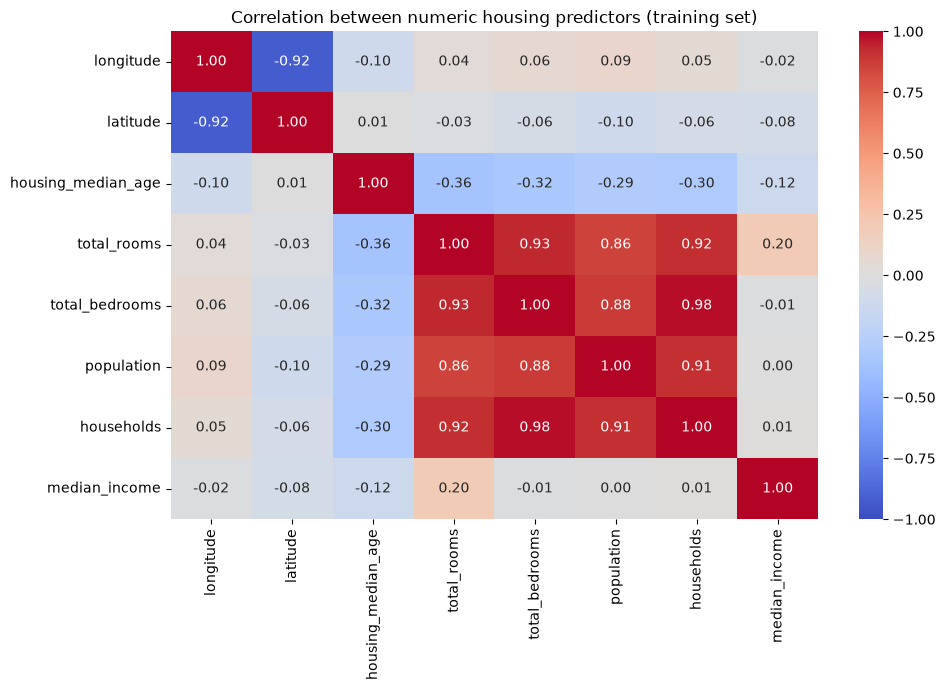

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_train = X_train.select_dtypes(include="number")
correlations = numeric_train.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlation between numeric housing predictors (training set)")
plt.tight_layout()
plt.show()

The training data shows strong correlations among the housing counts. Total bedrooms and households have the strongest positive correlation (0.98), followed by total rooms and total bedrooms (0.93). Latitude and longitude also have a strong negative correlation (−0.92), reflecting California’s northwest–southeast geography.

These relationships can make individual OLS coefficients sensitive to the training sample. We retain both coordinates because they jointly describe location, and we compare OLS with Ridge and Lasso to evaluate how regularization affects test performance.

The heatmap shows pairwise correlations and can miss cases where one predictor is closely related to a combination of several others.


## Feature engineering

We calculate rooms per household by dividing total rooms by the number of households. We then multiply rooms per household by median income to create an interaction feature. This lets the models estimate how the relationship between income and house value varies with rooms per household.

In [8]:
def add_housing_features(data):
    features = data.copy()

    # A zero household count would make the ratio undefined.
    households = features["households"].replace(0, float("nan"))
    features["rooms_per_household"] = features["total_rooms"] / households
    features["income_x_rooms_per_household"] = (
        features["median_income"] * features["rooms_per_household"]
    )

    return features


X_train_features = add_housing_features(X_train)
X_test_features = add_housing_features(X_test)

print("Training shape:", X_train_features.shape)
print("Test shape:", X_test_features.shape)

X_train_features[
    ["median_income", "rooms_per_household", "income_x_rooms_per_household"]
].head()

Training shape: (16512, 11)
Test shape: (4128, 11)


,median_income,rooms_per_household,income_x_rooms_per_household
14196,3.2596,5.017657,16.355553
8267,3.8125,4.473545,17.055390
17445,4.1563,5.645833,23.465777
14265,1.9425,4.002817,7.775472
2271,3.5542,6.268421,22.279222


In [9]:
engineered_columns = ["rooms_per_household", "income_x_rooms_per_household"]

display(
    X_train_features[engineered_columns]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
rooms_per_household,16512.0,5.44,2.39,0.89,4.45,5.24,6.06,7.65,10.32,141.91
income_x_rooms_per_household,16512.0,22.62,17.55,0.86,11.71,18.10,28.01,53.47,89.54,333.34


In [10]:
inspection_columns = [
    "total_rooms",
    "households",
    "median_income",
    "rooms_per_household",
    "income_x_rooms_per_household",
]

for feature in engineered_columns:
    print(f"Five training rows with the highest {feature}")
    display(X_train_features.nlargest(5, feature)[inspection_columns].round(2))

Five training rows with the highest rooms_per_household


,total_rooms,households,median_income,rooms_per_household,income_x_rooms_per_household
1914,1561.0,11.0,1.88,141.91,266.08
12447,2809.0,45.0,1.62,62.42,100.84
1913,2967.0,48.0,4.07,61.81,251.66
11862,958.0,16.0,2.62,59.88,157.17
1912,1463.0,26.0,4.97,56.27,279.94


Five training rows with the highest income_x_rooms_per_household


,total_rooms,households,median_income,rooms_per_household,income_x_rooms_per_household
1566,200.0,9.0,15.00,22.22,333.34
1912,1463.0,26.0,4.97,56.27,279.94
1914,1561.0,11.0,1.88,141.91,266.08
12430,7437.0,302.0,10.29,24.63,253.52
1913,2967.0,48.0,4.07,61.81,251.66


The training median was 5.24 rooms per household, and the 99th percentile was 10.32. Row 1914 had the highest ratio: 1,561 rooms divided by 11 households gives 141.91 rooms per household. The small household count explains how the ratio became so large.

Row 1566 had the highest income interaction (333.34). It combined 22.22 rooms per household with a median household income of approximately $150,000. Both extreme values are consistent with the recorded inputs, so we retain these observations for the model comparison.

## Preprocess the predictors

For each numeric predictor, we fill missing values with its training median and standardize its values. We one-hot encode `ocean_proximity` so the models can use the categories without assuming an order among them.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = X_train_features.select_dtypes(include="number").columns.tolist()
categorical_columns = ["ocean_proximity"]

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

category_encoder = OneHotEncoder(drop="first", handle_unknown="ignore")

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("category", category_encoder, categorical_columns),
])

print(f"Numeric predictors: {len(numeric_columns)}")
print(f"Categorical predictors: {len(categorical_columns)}")

Numeric predictors: 10
Categorical predictors: 1


## Fit the Ordinary Least Squares baseline

In [12]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression

ols_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("regression", LinearRegression()),
])

ols_model.fit(X_train_features, y_train)

fitted_preprocessor = ols_model.named_steps["preprocess"]
print(f"Training rows used: {len(y_train):,}")
print(f"Features after preprocessing: {len(fitted_preprocessor.get_feature_names_out())}")

Training rows used: 16,512
Features after preprocessing: 14


## Tune Ridge and Lasso with cross-validation

We select the regularization strength for each model using five-fold cross-validation on the training data. Each fold learns its own imputation values, scaling parameters, and category encoding. We reserve the test set for the final model comparison.

In [13]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

model_settings = {
    "Ridge": (Ridge(), [0.01, 0.1, 1, 10, 100, 1000]),
    "Lasso": (Lasso(max_iter=20000), [0.1, 1, 10, 100, 1000, 10000]),
}

tuned_models = {}
tuning_searches = {}
tuning_results = []

for name, (regressor, alphas) in model_settings.items():
    pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("regression", regressor),
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"regression__alpha": alphas},
        scoring="neg_root_mean_squared_error",
        cv=cv,
        refit=True,
    )
    search.fit(X_train_features, y_train)
    tuning_searches[name] = search

    tuned_models[name] = search.best_estimator_
    tuning_results.append({
        "Model": name,
        "Best alpha": search.best_params_["regression__alpha"],
        "Mean validation RMSE ($)": -search.best_score_,
    })

display(pd.DataFrame(tuning_results).set_index("Model").round(2))

,Best alpha,Mean validation RMSE ($)
Model,,
Ridge,1,68485.5
Lasso,10,68490.9


### Cross-validation results

Ridge selected `alpha=1` and achieved a mean validation RMSE of $68,485.50. Lasso selected `alpha=10` and achieved $68,490.90. The two models performed similarly across the five folds on average, with only $5.40 separating their mean RMSE values. Both selected alphas were inside their search ranges. The held-out test set remains reserved for the final comparison with OLS.

In [14]:
from sklearn.model_selection import cross_val_score

ols_scores = cross_val_score(
    ols_model,
    X_train_features,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

validation_comparison = pd.Series(
    {
        "OLS": -ols_scores.mean(),
        "Ridge": -tuning_searches["Ridge"].best_score_,
        "Lasso": -tuning_searches["Lasso"].best_score_,
    },
    name="Mean validation RMSE ($)",
)

display(validation_comparison.rename_axis("Model").to_frame().round(2))

,Mean validation RMSE ($)
Model,
OLS,68494.83
Ridge,68485.50
Lasso,68490.90


## Held-out test results

We evaluate OLS, Ridge, and Lasso on the same test set. RMSE and MAE measure prediction error in US dollars. RMSE gives larger errors more weight. R² measures the proportion of variation in median house value explained by each model on this test set.

In [15]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

models = {"OLS": ols_model, **tuned_models}
test_predictions = {}
test_results = []

for name, model in models.items():
    predicted = model.predict(X_test_features)
    test_predictions[name] = predicted

    test_results.append({
        "Model": name,
        "RMSE ($)": root_mean_squared_error(y_test, predicted),
        "MAE ($)": mean_absolute_error(y_test, predicted),
        "R²": r2_score(y_test, predicted),
    })

test_metrics = pd.DataFrame(test_results).set_index("Model")
display(test_metrics.round({"RMSE ($)": 2, "MAE ($)": 2, "R²": 4}))

,RMSE ($),MAE ($),R²
Model,,,
OLS,69841.73,50641.87,0.6278
Ridge,69850.54,50649.14,0.6277
Lasso,69852.99,50648.00,0.6276


On the 4,128 held-out census block groups, OLS achieved an RMSE of $69,841.73, an MAE of $50,641.87, and an R² of 0.6278. Its predictions differed from the recorded median house values by about $50,642 on average in absolute terms. All three models explained approximately 63% of the variation in the test target, and their RMSE values were within $12 of one another.

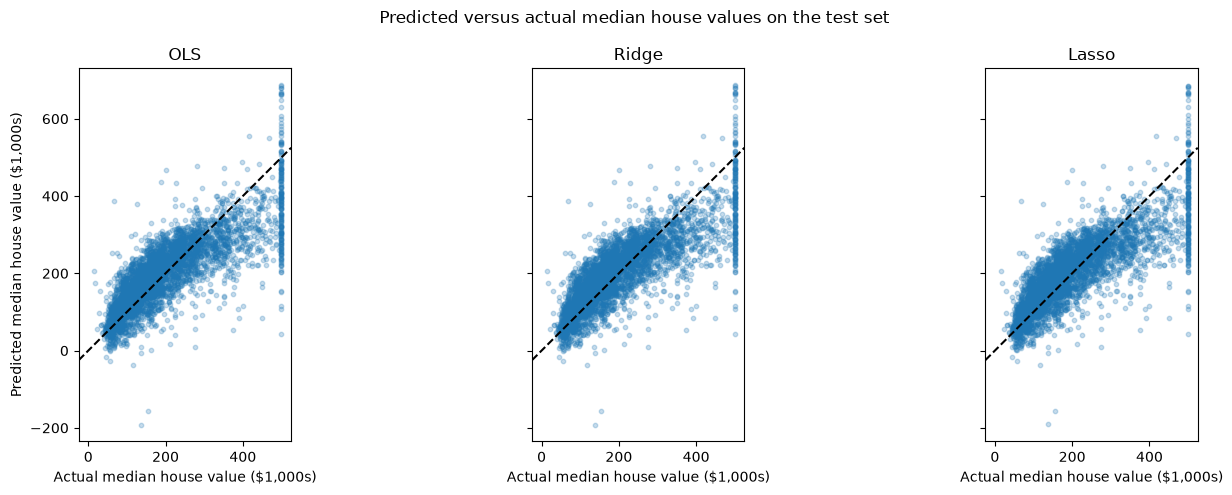

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax, (name, predicted) in zip(axes, test_predictions.items()):
    # Show values in thousands of dollars for readable axis labels.
    ax.scatter(y_test / 1000, predicted / 1000, s=10, alpha=0.25)
    ax.axline((0, 0), slope=1, color="black", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual median house value ($1,000s)")
    ax.set_aspect("equal", adjustable="box")

axes[0].set_ylabel("Predicted median house value ($1,000s)")
fig.suptitle("Predicted versus actual median house values on the test set")
fig.tight_layout()
plt.show()

## Residual error analysis

We calculate each residual as the recorded median house value minus the predicted value. A positive residual means the model underestimated the value, and a negative residual means it overestimated the value. For example, a residual of +$50,000 means the prediction was $50,000 too low.

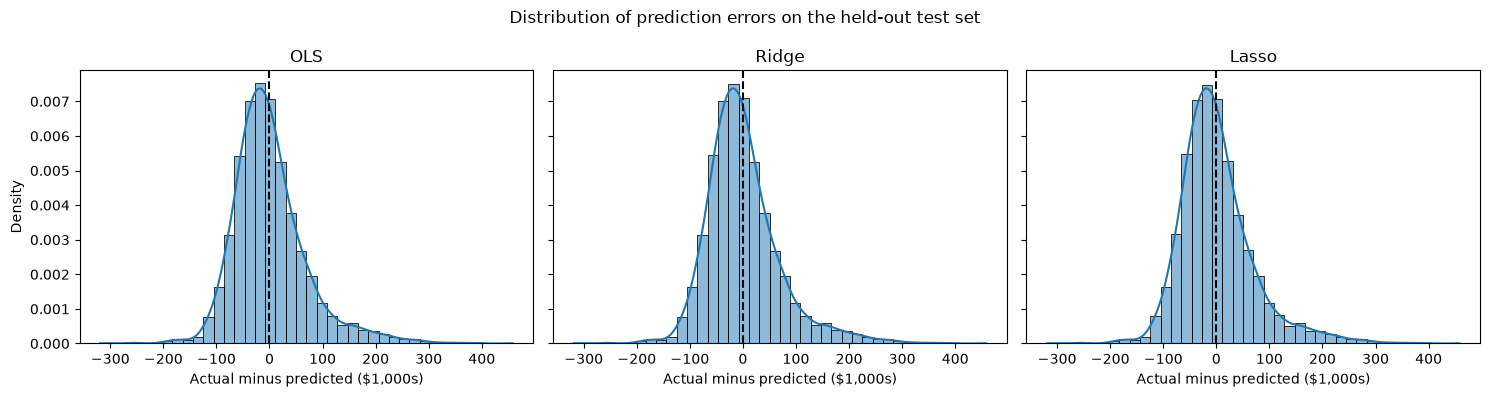

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, (name, predicted) in zip(axes, test_predictions.items()):
    residuals = (y_test - predicted) / 1000

    sns.histplot(residuals, bins=40, stat="density", kde=True, ax=ax)
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual minus predicted ($1,000s)")

axes[0].set_ylabel("Density")
fig.suptitle("Distribution of prediction errors on the held-out test set")
fig.tight_layout()
plt.show()

## Conclusion

OLS, Ridge, and Lasso produced similar prediction errors on the 4,128 held-out census block groups. OLS had the lowest test RMSE ($69,841.73), although only $11.26 separated the lowest and highest RMSE. On this split, regularization made little difference to predictive performance.

All three residual distributions peak slightly below zero and have a longer positive tail. The models sometimes substantially underestimated median house values, a pattern also visible for many higher-valued block groups in the predicted-versus-actual plots.